In [5]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.integrate import solve_ivp
from numba import jit

# Hyperbolic CNC with Hyperbolic burden

In [60]:
def ssa_hyperbolic(x0,y0,y_div):
    del_t=0.05
    x=[x0]               #plasmid count count 
    t_x=[0]              #reaction time of fully-observed trajectory
    i=0
    y=y0
    
    while y<y_div:
        a=k_tr*x[i]/(1+x[i]/(y*K))
        beta=b+beta0/(1+x[i]*nu)
        t_x=np.append(t_x,[t_x[i]+del_t])
        y=y0*np.exp(beta*(t_x[i+1]-t_x[i]))   #volume at replication
        if np.random.uniform(0,1,1)<a*del_t:
            x=np.append(x,[x[i]+1])
        else:
            x=np.append(x,[x[i]])
        if y>=y_div:
            x[i+1]=x[i]
            t_x[i+1]=t_x[i]+np.log(y_div/y0)/beta
            y=y_div   #volume at replication
        y0=y
        i+=1
    print(x,y)
    return x,t_x,y

def single_hyperbolic(x0,gen,y0,y_div):
    x=[x0]
    t=np.array([0])
    div_time=np.zeros(gen)
    for i in range(gen):
        if x0>=0:
            xx,tt,yy=ssa_hyperbolic(x0,y0,y_div)
            x=np.append(x,xx)
            t=np.append(t,t[-1]+tt)
            y0=yy/2
            x0=np.random.binomial(xx[-1],0.5)
            div_time[i]=t[-1]
            #print(x0)
            print('############# divide ################')
        #else:
        #    x=np.append(x,[0])
        #    t=np.append(t,t[-1]+1)
            
    return x,t,div_time

def plot_stairs(x,t):
    l=len(t)
    for i in range(l-1):
        vec_t=[t[i],t[i+1]]
        vec_x=[x[i],x[i]]
        plt.plot(vec_t,vec_x,color='k')
        if x[i]-x[i+1]>0:
            plt.vlines(t[i+1],x[i],x[i+1],color='red')
        else:
            plt.vlines(t[i+1],x[i],x[i+1],color='k')
    plt.ylim([0,max(x)+1])
    plt.xlabel('time')
    plt.ylabel('Plasmid copy number')
    return None

[ 6  6  6  6  6  6  6  6  6  6  6  6  6  6  6  6  6  6  6  6  6  6  6  6
  6  6  6  6  6  6  6  6  6  6  6  6  6  6  6  6  6  6  6  6  6  6  6  6
  6  6  6  6  6  6  6  6  6  6  6  6  6  6  6  6  6  6  6  6  6  6  6  6
  6  6  6  6  6  6  6  6  6  6  6  6  6  6  7  7  7  7  7  7  7  7  7  8
  8  8  8  8  8  8  8  9  9  9  9  9 10 10 10 10 10 10 10 10 10 10 10 10
 10 10 10 10 10 10 10 11 12 12 12 12 12 12 12 12 13 13 13 13 13 13 13 13
 13 13 13 13 13 13 13 14 14 14 14 14 14 14 14 14 14 14 14 14 14 14 15 15
 15 15] 1
############# divide ################
[ 5  5  5  5  5  5  5  5  5  5  5  5  5  5  5  5  5  5  5  5  5  5  5  5
  5  5  5  5  5  6  6  6  6  6  6  6  6  6  6  6  6  6  6  6  6  6  6  6
  6  6  7  7  7  7  7  7  7  7  7  7  7  7  7  8  8  8  8  8  8  8  8  8
  8  9  9  9 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10
 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10
 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10
 10

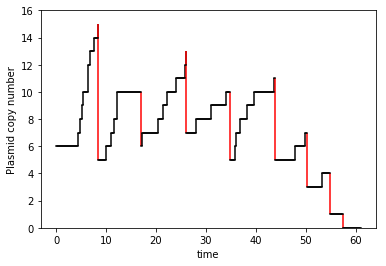

In [63]:
k_tr=1
K=1
beta0=0.4
x0=6
y_div=1
y0=y_div/2
nu=0.5
b=0
gen=10
x,t,div_time=single_hyperbolic(x0,gen,y0,y_div)
plot_stairs(x,t)

(0, 10.101964597203857)

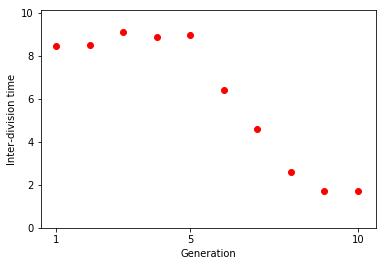

In [67]:
f=plt.figure()
times=np.append([0],div_time)
for i in range(len(times)-1):
    inter=times[i+1]-times[i]
    #if times[i+1]-times[i]<0:
    #    inter=0
    plt.scatter([i+1],[inter],color='red')
plt.xticks([1,int(gen/2),gen])
plt.xlabel('Generation')
plt.ylabel('Inter-division time')
plt.ylim([0,1+max(np.append(times,[times[-1]+1])-np.append([0],times))])

In [59]:
times

array([ 0.        , 11.32073919, 21.96019713, 31.70910535, 40.21376797,
       43.85843785, 48.2420417 , 51.70777761,  0.        ,  0.        ,
        0.        ])

[1 1 1 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 3 3 3 3 3 3 4 4 4 4 4 4 4 4 4 4 4] 1
############# divide ################
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1] 1
############# divide ################
[1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 3 3 3 3 3 3 4 4
 4 4 4 4 4 5 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6 6] 1
############# divide ################
[ 4  4  4  4  4  4  4  4  4  4  4  4  4  4  4  4  5  5  5  5  5  5  6  6
  6  6  6  6  6  6  6  6  6  6  7  7  7  8  8  8  8  8  8  8  8  8  8  8
  8  8  8  8  8  8  8  8  8  8  8  8  8  9  9  9  9  9  9 10 10 10 10 10
 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 10 11 11 11 11
 11 11 11 11 12 12 12 12 12 13 13 13 14 14 14 14 14 14 14 15 15 15 15 15
 15 16 16 16 16 16 16 16 16 16 16 16 16 16 17 17 18 18 18 18 18 18 18 18
 18 18 18 18 18 18 18] 1
############# divide ################
[ 7  7  7  7  7  7

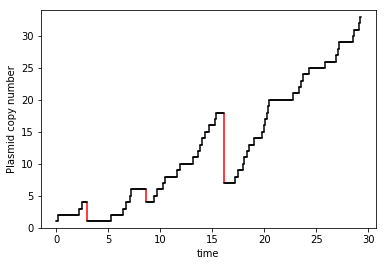

In [74]:
k_tr=1
K=3
beta0=0.5
x0=1
y_div=1
y0=y_div/2
nu=0.5
b=0
gen=5
x,t,div_time=single_hyperbolic(x0,gen,y0,y_div)
plot_stairs(x,t)